# CashCast: model training

This notebook walks through how the forecasting model is built, step by step. It uses the **same code as the API** (`model/features.py` and `model/train.py`), so what you see here is exactly what runs in production. The last step saves the model the API loads.

**Goal:** predict each ATM's cash demand for the next day (target `Cash_Demand_Next_Day`) with accuracy of at least 85% (accuracy = 100 − MAPE).

## Step 1 - Import libraries

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Find the project folder, whether the notebook is opened from Notebook/ or from the project root
root = Path.cwd() if (Path.cwd() / 'model' / 'train.py').is_file() else Path.cwd().parent
sys.path.insert(0, str(root))

from model.features import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, TARGET, build_features
from model.train import DATA_PATH, TEST_START, build_estimator, mean_absolute_percentage_error, replay_daily_policy

plt.rcParams.update({'figure.figsize': (10, 3.8), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})
print('Project folder:', root)

Project folder: /home/claude/w/ATM_Cash_Demand


## Step 2 - Load the dataset

10 ATMs x 600 days. Each row is one ATM on one day; `Cash_Demand_Next_Day` is what the ATM paid out the following day.

In [2]:
data = pd.read_csv(DATA_PATH, parse_dates=['Date']).sort_values(['ATM_ID', 'Date']).reset_index(drop=True)
print(data.shape, '|', data['Date'].min().date(), 'to', data['Date'].max().date())
print('Missing values:', int(data.isna().sum().sum()), '| duplicate ATM-days:', int(data.duplicated(['ATM_ID', 'Date']).sum()))
data.head()

(6000, 22) | 2024-01-01 to 2025-08-22
Missing values: 0 | duplicate ATM-days: 0


,ATM_ID,Date,Day_of_week,Location,City,Day,Month,Year,ATM_Capacity,Total_Current_Cash,...,No_of_Deposits,No_of_Withdraws,Temperature,Weather_Condition,Holiday_Flag,Festival_Flag,Previous_Day_Cash_Level,Cash_Demand_Next_Day,Replenishment_Required,Replenishment_Amount
0,ATM001,2024-01-01,Monday,Mall,Mumbai,1,1,2024,3000000,2430300,...,21,217,12.3,Cloudy,0,0,3000000,707800,0,0
1,ATM001,2024-01-02,Tuesday,Mall,Mumbai,2,1,2024,3000000,1855700,...,19,210,13.5,Sunny,0,0,2430300,638000,0,0
2,ATM001,2024-01-03,Wednesday,Mall,Mumbai,3,1,2024,3000000,1291700,...,12,193,12.2,Sunny,0,0,1855700,587200,0,0
3,ATM001,2024-01-04,Thursday,Mall,Mumbai,4,1,2024,3000000,804000,...,13,145,9.3,Sunny,0,0,1291700,678000,0,0
4,ATM001,2024-01-05,Friday,Mall,Mumbai,5,1,2024,3000000,281100,...,22,171,15.8,Foggy,0,0,804000,582600,1,2720000


## Step 3 - Features and target

Besides the raw columns the model gets **time-series features**: withdrawals from 1 and 7 days ago, the average of the previous 7 days (the current day is not included), and the calendar flags for *tomorrow* (holiday, festival, weekday), which are known in advance.

In [3]:
features = build_features(data)
print('Target:', TARGET)
print('Categorical:', CATEGORICAL_FEATURES)
print('Numeric    :', NUMERIC_FEATURES)
features[FEATURES].head()

Target: Cash_Demand_Next_Day
Categorical: ['ATM_ID', 'Location', 'City', 'Weather_Condition']
Numeric    : ['ATM_Capacity', 'Total_Current_Cash', 'Total_Withdraw_Cash', 'Total_deposite_Cash', 'No_of_Deposits', 'No_of_Withdraws', 'Temperature', 'Holiday_Flag', 'Festival_Flag', 'Previous_Day_Cash_Level', 'Day', 'Month', 'Year', 'Day_of_week', 'withdrawals_lag_1', 'withdrawals_lag_7', 'withdrawals_rolling_7', 'next_day_holiday', 'next_day_festival', 'next_day_weekday', 'payday_flag']


,ATM_ID,Location,City,Weather_Condition,ATM_Capacity,Total_Current_Cash,Total_Withdraw_Cash,Total_deposite_Cash,No_of_Deposits,No_of_Withdraws,...,Month,Year,Day_of_week,withdrawals_lag_1,withdrawals_lag_7,withdrawals_rolling_7,next_day_holiday,next_day_festival,next_day_weekday,payday_flag
0,ATM001,Mall,Mumbai,Cloudy,3000000,2430300,713500,143800,21,217,...,1,2024,0.0,0.0,0.0,0.000000,0.0,0.0,1,1
1,ATM001,Mall,Mumbai,Sunny,3000000,1855700,707800,133200,19,210,...,1,2024,1.0,713500.0,0.0,713500.000000,0.0,0.0,2,0
2,ATM001,Mall,Mumbai,Sunny,3000000,1291700,638000,74000,12,193,...,1,2024,2.0,707800.0,0.0,710650.000000,0.0,0.0,3,0
3,ATM001,Mall,Mumbai,Sunny,3000000,804000,587200,99500,13,145,...,1,2024,3.0,638000.0,0.0,686433.333333,0.0,0.0,4,0
4,ATM001,Mall,Mumbai,Foggy,3000000,281100,678000,155100,22,171,...,1,2024,4.0,587200.0,0.0,661625.000000,0.0,0.0,5,0


## Step 4 - Chronological train/test split

Time series must never be shuffled: the model learns from the past and is tested on later days it has not seen. Everything before 2025-05-01 is training data; the rest is the test period. The first 7 days of each ATM are skipped because the 7-day lag does not exist yet.

In [4]:
usable = data[TARGET].notna() & data.groupby('ATM_ID').cumcount().ge(7)
train = (data['Date'] < TEST_START) & usable
test = (data['Date'] >= TEST_START) & usable
X_train, y_train = features.loc[train, FEATURES], data.loc[train, TARGET]
X_test, y_test = features.loc[test, FEATURES], data.loc[test, TARGET]
print(f'Train rows: {train.sum():,}   Test rows: {test.sum():,}   Test starts: {TEST_START.date()}')

Train rows: 4,790   Test rows: 1,140   Test starts: 2025-05-01


## Step 5 - Train the model

One-hot encoding for the text columns and a `HistGradientBoostingRegressor` (the production model).

In [5]:
model = build_estimator().fit(X_train, y_train)
model

,steps,"[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numeric', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


## Step 6 - Performance on the unseen test period

The baseline is the simplest sensible forecast: tomorrow equals the average of the last 7 days. The model has to beat it.

In [6]:
prediction = np.maximum(0, model.predict(X_test))
actual = y_test.to_numpy(dtype=float)
baseline = features.loc[test, 'withdrawals_rolling_7'].to_numpy(dtype=float)

mape = mean_absolute_percentage_error(actual, prediction)
results = pd.DataFrame({
    'Model': {'MAE (Rs)': mean_absolute_error(actual, prediction), 'RMSE (Rs)': np.sqrt(mean_squared_error(actual, prediction)),
              'WAPE %': np.abs(actual - prediction).sum() / actual.sum() * 100, 'MAPE %': mape, 'Accuracy % (100 - MAPE)': 100 - mape, 'R2': r2_score(actual, prediction)},
    '7-day average': {'MAE (Rs)': mean_absolute_error(actual, baseline), 'RMSE (Rs)': np.sqrt(mean_squared_error(actual, baseline)),
              'WAPE %': np.abs(actual - baseline).sum() / actual.sum() * 100, 'MAPE %': mean_absolute_percentage_error(actual, baseline),
              'Accuracy % (100 - MAPE)': 100 - mean_absolute_percentage_error(actual, baseline), 'R2': r2_score(actual, baseline)},
}).round(2)
print('Target: accuracy >= 85%  ->', 'PASSED' if 100 - mape >= 85 else 'NOT MET')
results

Target: accuracy >= 85%  -> PASSED


,Model,7-day average
MAE (Rs),48498.36,82179.40
RMSE (Rs),64030.05,107411.31
WAPE %,8.23,13.94
MAPE %,8.15,13.90
Accuracy % (100 - MAPE),91.85,86.10
R2,0.82,0.50


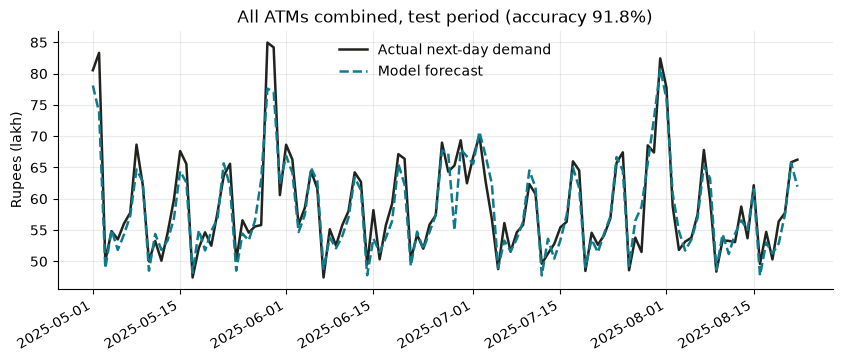

In [7]:
daily = pd.DataFrame({'actual': actual, 'predicted': prediction}, index=data.loc[test, 'Date']).groupby(level=0).sum() / 1e5
fig, ax = plt.subplots()
ax.plot(daily.index, daily['actual'], color='#20231e', lw=1.8, label='Actual next-day demand')
ax.plot(daily.index, daily['predicted'], color='#0f7b8a', lw=1.8, ls='--', label='Model forecast')
ax.set(title=f'All ATMs combined, test period (accuracy {100 - mape:.1f}%)', ylabel='Rupees (lakh)')
ax.legend(frameon=False); fig.autofmt_xdate(); plt.show()

## Step 7 - Accuracy for each ATM

The target must hold for every machine, not only on average.

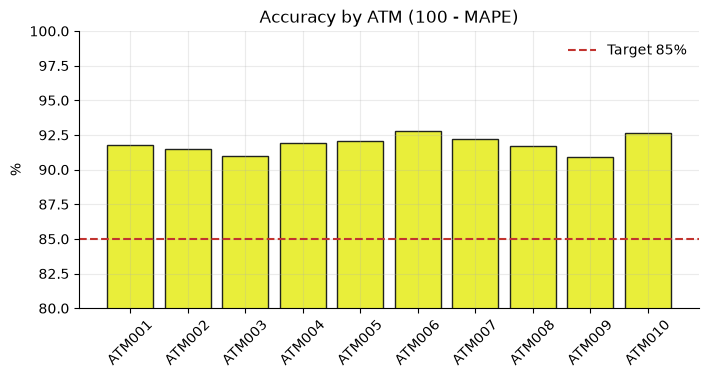

Lowest: ATM009 90.9%   Highest: ATM006 92.8%


In [8]:
frame = pd.DataFrame({'ATM_ID': data.loc[test, 'ATM_ID'].to_numpy(), 'actual': actual, 'predicted': prediction})
per_atm = frame.groupby('ATM_ID').apply(lambda g: 100 - mean_absolute_percentage_error(g['actual'].to_numpy(), g['predicted'].to_numpy()), include_groups=False)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(per_atm.index, per_atm.values, color='#e9ee3a', edgecolor='#20231e')
ax.axhline(85, color='#c2332f', ls='--', label='Target 85%'); ax.set_ylim(80, 100)
ax.set(title='Accuracy by ATM (100 - MAPE)', ylabel='%'); ax.legend(frameon=False); plt.xticks(rotation=45); plt.show()
print(f'Lowest: {per_atm.idxmin()} {per_atm.min():.1f}%   Highest: {per_atm.idxmax()} {per_atm.max():.1f}%')

## Step 8 - Why HistGradientBoosting? Comparison with the earlier Random Forest

The first version of this project used a 150-tree Random Forest. Here both are trained on the same features and split.

In [9]:
forest = RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=136, n_jobs=-1)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
forest_model = make_pipeline(ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES), ('n', 'passthrough', NUMERIC_FEATURES)]), forest).fit(X_train, y_train)
forest_prediction = np.maximum(0, forest_model.predict(X_test))
pd.DataFrame({
    'HistGradientBoosting (used)': [mape, 100 - mape, mean_absolute_error(actual, prediction), r2_score(actual, prediction)],
    'Random Forest (150 trees)': [mean_absolute_percentage_error(actual, forest_prediction), 100 - mean_absolute_percentage_error(actual, forest_prediction), mean_absolute_error(actual, forest_prediction), r2_score(actual, forest_prediction)],
}, index=['MAPE %', 'Accuracy %', 'MAE (Rs)', 'R2']).round(2)

,HistGradientBoosting (used),Random Forest (150 trees)
MAPE %,8.15,8.82
Accuracy %,91.85,91.18
MAE (Rs),48498.36,52699.77
R2,0.82,0.79


## Step 9 - What drives the forecast?

Permutation importance: how much the error grows when one feature is scrambled. Bigger means more important.

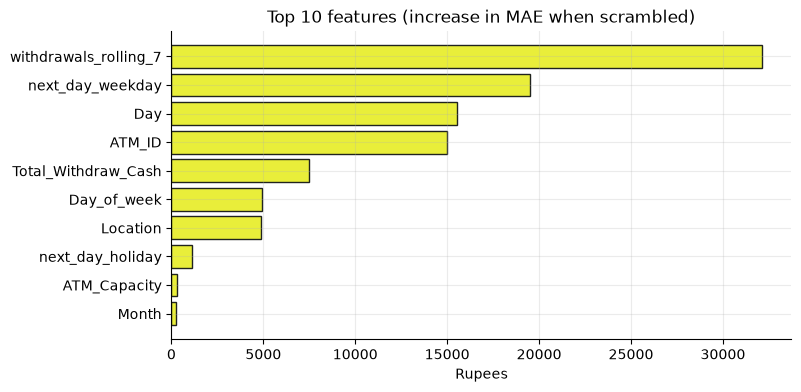

In [10]:
importance = permutation_importance(model, X_test, y_test, n_repeats=5, random_state=136, scoring='neg_mean_absolute_error')
ranking = pd.Series(importance.importances_mean, index=FEATURES).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ranking.index, ranking.values, color='#e9ee3a', edgecolor='#20231e')
ax.set(title='Top 10 features (increase in MAE when scrambled)', xlabel='Rupees'); plt.show()

## Step 10 - Does the forecast reduce cash-outs?

Each ATM is replayed day by day with its real withdrawals and deposits under two refill rules. **Fixed rule:** refill when cash is below 25% of capacity. **Forecast rule:** refill when cash is below 1.2 x tomorrow's forecast + 5% of capacity. This is a simulation of the policies, not real operations. Target: at least 70% fewer cash-outs.

Cash-outs: 26 -> 0  (100% fewer, target 70%)   Refill trips: 302 -> 346


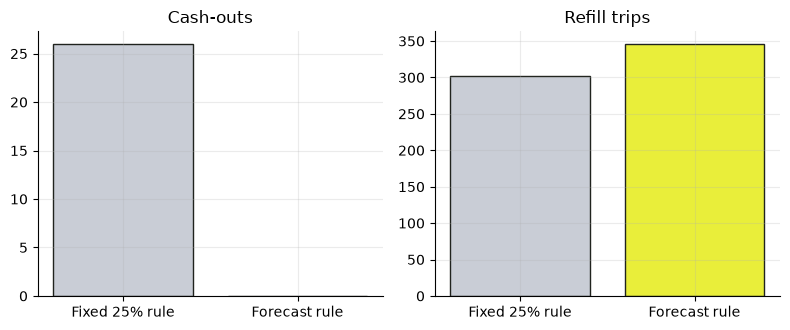

In [11]:
replay = data.loc[test].assign(forecast=prediction)
fixed = replay_daily_policy(replay, forecast_driven=False)
smart = replay_daily_policy(replay, forecast_driven=True)
reduction = (fixed['cashouts'] - smart['cashouts']) / max(fixed['cashouts'], 1) * 100
print(f"Cash-outs: {fixed['cashouts']} -> {smart['cashouts']}  ({reduction:.0f}% fewer, target 70%)   Refill trips: {fixed['refill_trips']} -> {smart['refill_trips']}")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, key, title in zip(axes, ['cashouts', 'refill_trips'], ['Cash-outs', 'Refill trips']):
    ax.bar(['Fixed 25% rule', 'Forecast rule'], [fixed[key], smart[key]], color=['#c9cdd6', '#e9ee3a'], edgecolor='#20231e'); ax.set_title(title)
plt.tight_layout(); plt.show()

## Step 11 - Save the model the API uses

`train.main()` repeats the training above and writes `model/cashcast_model.joblib` and `model/metrics.json`, which the FastAPI backend and the dashboard read. Running this cell is what connects the notebook to the website.

In [12]:
from model.train import MODEL_PATH, METRICS_PATH, main as train_and_save

train_and_save()
print('\nSaved:', MODEL_PATH.name, '+', METRICS_PATH.name)

{
  "test_start": "2025-05-01",
  "test_rows": 1140,
  "mape_percent": 8.154047462906009,
  "accuracy_percent": 91.84595253709399,
  "mae": 48498.35521121406,
  "r2": 0.8210328866230231,
  "baseline_mape_percent": 13.90227054945521,
  "atm_accuracy": {
    "ATM001": 91.80768822911779,
    "ATM002": 91.50826730941411,
    "ATM003": 90.94899717328545,
    "ATM004": 91.93971113430796,
    "ATM005": 92.04057806297395,
    "ATM006": 92.8131025877643,
    "ATM007": 92.17666016809784,
    "ATM008": 91.67335302630741,
    "ATM009": 90.90274037001657,
    "ATM010": 92.64842730965456
  },
  "model_trained": true,
  "backtest": {
    "simulation": true,
    "method": "day-by-day replay per ATM; balances carry forward after simulated refills, withdrawals, and recorded deposits",
    "fixed_threshold": {
      "cashouts": 26,
      "refill_trips": 302
    },
    "forecast_threshold": {
      "cashouts": 0,
      "refill_trips": 346
    },
    "cashout_reduction_percent": 100.0
  }
}

Saved: cashcas

## Step 12 - Check that the saved model loads and predicts

In [13]:
loaded = joblib.load(MODEL_PATH)
latest = data.groupby('ATM_ID').tail(1).index
sample = pd.DataFrame({'ATM': data.loc[latest, 'ATM_ID'].to_numpy(), 'City': data.loc[latest, 'City'].to_numpy(),
                       'Cash now (Rs)': data.loc[latest, 'Total_Current_Cash'].to_numpy(),
                       'Forecast for tomorrow (Rs)': np.maximum(0, loaded.predict(features.loc[latest, FEATURES]))}).round(0)
sample

,ATM,City,Cash now (Rs),Forecast for tomorrow (Rs)
0,ATM001,Mumbai,1051200,727371.0
1,ATM002,Delhi,1037200,813727.0
2,ATM003,Bengaluru,1011900,605690.0
3,ATM004,Ghaziabad,2015400,580614.0
4,ATM005,Lucknow,2271800,761250.0
5,ATM006,Jaipur,1446300,689874.0
6,ATM007,Pune,522300,513506.0
7,ATM008,Kanpur,2044900,548825.0
8,ATM009,Patna,269300,580699.0
9,ATM010,Nagpur,399800,371914.0
